In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google.colab'

In [1]:
import numpy as np
import sys
sys.path.append("..")
from data.data_loader import DataLoader
from training_split import split_normal, split_leave_n_out_generator
from data.data_configs import *
from classification.models.csp.prepare_data_for_csp import prepare_data_for_csp
from classification.training_split import split_normal, split_leave_n_out_generator
from classification.models.csp.train_csp import train_csp
from classification.models.csp.plot_csp import visualize_csp_analysis

In [2]:
X, y, subject_ids = DataLoader.load_labeled_eeg_data(subjects=SUBJECTS[:1], channels=CBRAMOD_CHANNELS, labeled_eeg_data_dir=LABELED_EEG_DATA_DIR)


LOADING EEG DATA

Epoch settings:
  Window: [-500, 1000] ms
  Epoch: [-200, 800] ms (indices 150:650)
  Sampling rate: 500 Hz

Loading from 1 subjects...

✓ Data loaded:
  Total trials: 2452
  From 1 subjects
  Channels: 19
  Time points: 500
  Duration: 1000 ms

Label distribution:
  Label False: 1195 samples (48.74%)
  Label True: 1257 samples (51.26%)


In [3]:
X.shape

(2452, 19, 500)

In [4]:
X, y = prepare_data_for_csp(X, y)

--- Standard CSP Data Prep (Fs=500Hz) ---
Applying Bandpass Filter (0.5 - 40 Hz)...


~/Code/Eye_EEG/classification/../classification/models/csp/prepare_data_for_csp.py:22: RuntimeWarning: filter_length (3301) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs.filter(l_freq=0.5, h_freq=40.0, verbose=False)


Data Ready. Shape: (2452, 19, 500)


In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = split_normal(X, y)


RANDOM TRAIN/VAL/TEST SPLIT

Train: 1470 samples (60.0%)
  {False: 717, True: 753}

Val:   491 samples (20.0%)
  {False: 239, True: 252}

Test:  491 samples (20.0%)
  {False: 239, True: 252}


In [6]:
results = train_csp(X_train, y_train, X_val, y_val, X_test, y_test, 
                          n_components=4, 
                          clf_type='lda')

Training CSP-LDA | Components: 4
Computing rank from data with rank=None
    Using tolerance 2.2e+02 (2.2e-16 eps * 19 dim * 5.2e+16  max singular value)
    Estimated rank (data): 19
    data: rank 19 computed from 19 data channels with 0 projectors
Reducing data rank from 19 -> 19
Estimating class=False covariance using EMPIRICAL
Done.
Estimating class=True covariance using EMPIRICAL
Done.
[Status] Evaluating on TEST set...
Balanced Acc: 0.5202



 CSP SPATIAL PATTERNS (Topomaps)
 -> Pattern 1 (Top Left): Maximizes variance for Class 0
 -> Last Pattern (Bottom Right): Maximizes variance for Class 1
NOTE: plot_patterns() is a legacy function. New code should use get_spatial_filter_from_estimator(clf, info=info).plot_patterns().


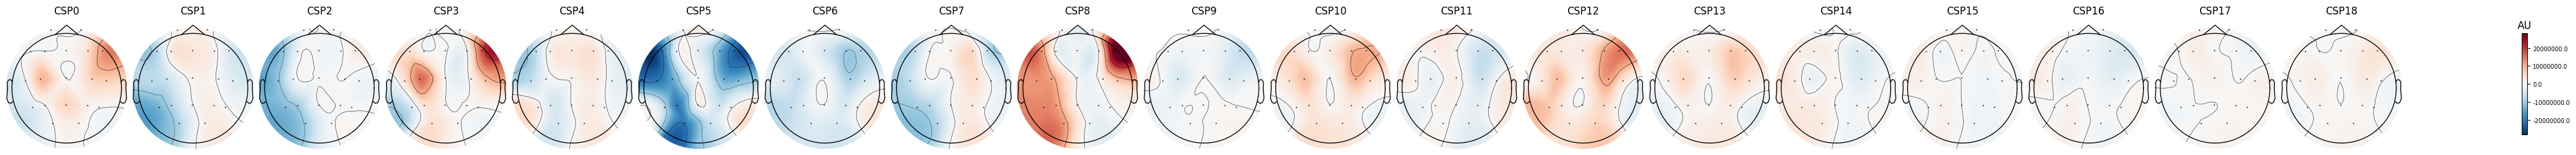


 CSP FEATURE DISTRIBUTIONS (Separability)
 -> Ideally, Blue (Class 0) and Red (Class 1) distributions should be separate.


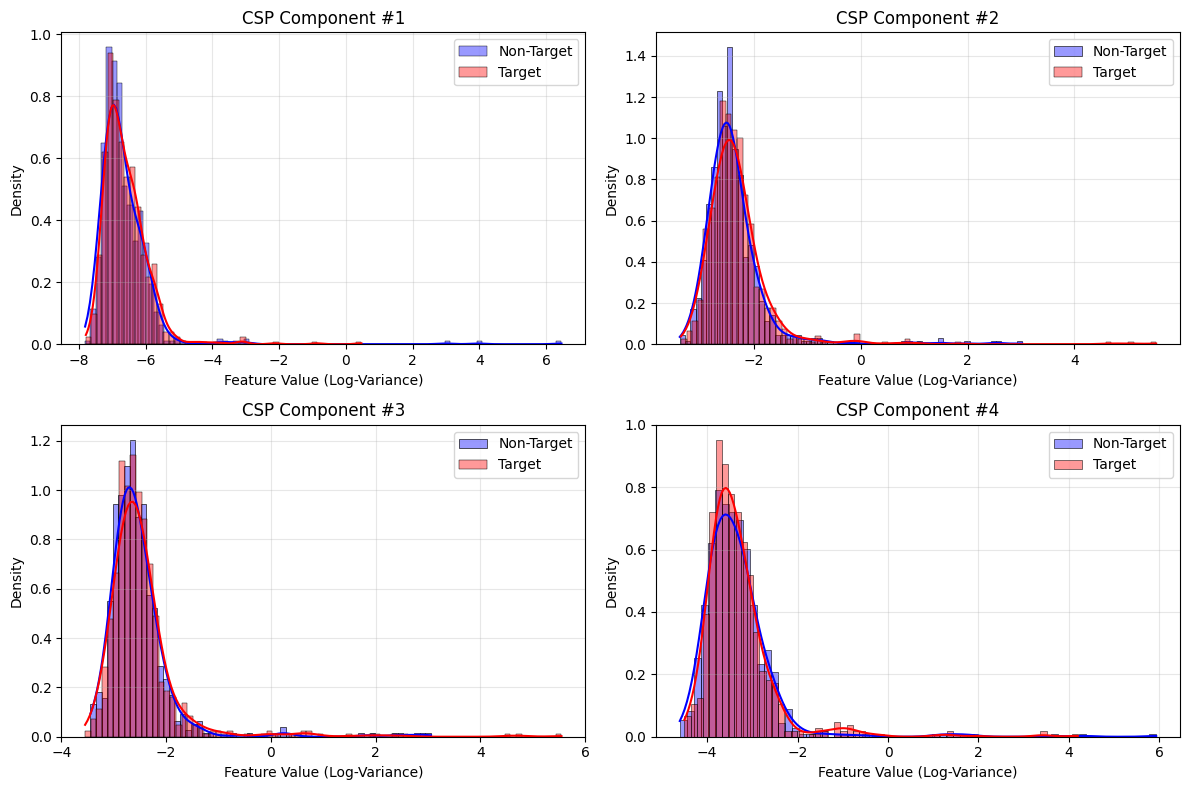

In [7]:
best_model = results['model']


visualize_csp_analysis(best_model, X_train, y_train, 
                       ch_names=CBRAMOD_CHANNELS)